# Строгая проверка: k и отбор признаков внутри каждого шага валидации

В EDA (notebooks/01_eda_prices_target) k и отбор признаков считались на **всём трейне** (апрель 2015 – сентябрь 2023), а модели потом сравнивались на последних 36 месяцах того же трейна. Значит, выбор k и признаков уже «видел» месяцы валидации.

**Строгий вариант:** на каждом шаге прогноза со скользящим началом всё, что выбирается по данным, считается **только по строкам, ответ для которых уже известен**:
- **k** — наклон цены карбамида по газу;
- **отбор признаков** — те же два шага, что в разделе 2.6 ноутбука 01_eda_prices_target: связь с целью выше порога случайности, затем удаление дублей (|r| > 0,75);
- **масштабирование** признаков.

**Деление:** трейн — апрель 2015 – сентябрь 2023, тест — октябрь 2023 – сентябрь 2026 (не трогаем). Валидация — внутри трейна: октябрь 2020 – сентябрь 2023 (36 мес., с кризисом) и отдельно спокойное окно январь 2018 – июнь 2021. Делим **по датам, а не по пропорции**: тест — последние 3 года (≈ 26% ряда), валидация — последние 3 года трейна.

In [ ]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.models.backtest import make_table_full, estimate_k, select_features, rolling_backtest, score, TEST_START

raw = pd.read_excel("../data/raw/CMO-Historical-Data-Monthly.xlsx", sheet_name="Monthly Prices", header=None)
header_row = raw.index[raw.astype(str).apply(lambda r: r.str.strip().str.startswith("Urea").any(), axis=1)][0]
columns = raw.iloc[header_row].fillna("").astype(str).str.strip().str.replace(r"\s*\*+$", "", regex=True)
body = raw.iloc[header_row + 2:].copy()
body.columns = columns
body = body[body.iloc[:, 0].astype(str).str.match(r"^\d{4}M\d{2}$")]
body.index = pd.to_datetime(body.iloc[:, 0].str.replace("M", "-") + "-01")
names = {
    "Crude oil, Brent": "brent", "Coal, Australian": "coal_aus", "Coal, South African": "coal_safr",
    "Natural gas, US": "gas_us", "Natural gas, Europe": "gas_europe", "Liquefied natural gas, Japan": "lng_japan",
    "Urea": "urea_price", "DAP": "dap", "TSP": "tsp", "Phosphate rock": "phosphate_rock", "Potassium chloride": "potash",
    "Maize": "maize", "Wheat, US HRW": "wheat", "Soybeans": "soybeans", "Rice, Thai 5%": "rice",
    "Sugar, world": "sugar", "Palm oil": "palm_oil", "Copper": "copper", "Iron ore, cfr spot": "iron_ore", "Aluminum": "aluminum",
}
prices = pd.DataFrame({new: pd.to_numeric(body[old].replace("…", np.nan), errors="coerce") for old, new in names.items()})
prices = prices.loc["2015-04":]
candidates = ["d_" + c for c in prices.columns if c != "urea_price"]
print("Кандидатов в признаки:", len(candidates), "| месяцев:", len(prices), "| тест с", TEST_START.date())

Кандидатов в признаки: 19 | месяцев: 138 | тест с 2023-10-01


## Модели
Все три обучаются на каждом шаге заново, только на известных строках (known):
1. **Возврат надбавки к норме** — k оценивается внутри шага, дальше как в 03: надбавка через h месяцев ~ текущая надбавка.
2. **Ridge с отбором признаков внутри шага** — признаки: месячные изменения рядов Pink Sheet, отобранные по known; цель — изменение цены (лог) через h месяцев.
3. **Ridge на всех 19 признаках** — без отбора, для сравнения: помогает ли отбор.

In [ ]:
log_k, log_features = [], []


def markup_model(known, now):
    k = estimate_k(known)
    log_k.append(k)
    x = known["price"] - k * known["gas"]
    y = known["y"] - k * known["gas"]
    slope, intercept = np.polyfit(x, y, 1)
    x_now = now["price"].iloc[0] - k * now["gas"].iloc[0]
    return k * now["gas"].iloc[0] + intercept + slope * x_now


def ridge_selected(known, now):
    features = select_features(known, candidates)
    log_features.append(features)
    if not features:
        return now["price"].iloc[0]
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(known[features], np.log(known["y"] / known["price"]))
    return now["price"].iloc[0] * np.exp(model.predict(now[features])[0])


def ridge_all(known, now):
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(known[candidates], np.log(known["y"] / known["price"]))
    return now["price"].iloc[0] * np.exp(model.predict(now[candidates])[0])

In [ ]:
windows = {"валидация: окт 2020 – сен 2023": ("2020-10", "2023-09"),
           "спокойно: янв 2018 – июн 2021": ("2018-01", "2021-06")}
models = {"возврат к норме (k внутри шага)": markup_model,
          "ridge, отбор внутри шага": ridge_selected,
          "ridge, все 19 признаков": ridge_all}

rows = []
selected_by_h = {}
for h in [1, 3]:
    table = make_table_full(prices, h)
    for wname, (start, end) in windows.items():
        origins = table.loc[start:end].index
        origins = origins[origins <= pd.Timestamp(end) - pd.DateOffset(months=h)]
        for mname, model in models.items():
            log_k.clear(); log_features.clear()
            res = score(rolling_backtest(table, h, model, origins))
            row = {"горизонт": h, "окно": wname, "модель": mname}
            for part in res.index:
                row[f"MSE/наивный: {part}"] = res.loc[part, "MSE модель / наивный"]
            if mname.startswith("возврат"):
                row["k: min–max"] = f"{min(log_k):.1f}–{max(log_k):.1f}"
            if mname == "ridge, отбор внутри шага" and wname.startswith("валидация"):
                selected_by_h[h] = list(log_features)
            rows.append(row)
result = pd.DataFrame(rows)
print("Отношение MSE модели к MSE наивного прогноза (меньше 1 — модель лучше):")
print(result.to_string(index=False))

Отношение MSE модели к MSE наивного прогноза (меньше 1 — модель лучше):
 горизонт                           окно                          модель  MSE/наивный: все  MSE/наивный: без кризиса  MSE/наивный: кризис k: min–max
        1 валидация: окт 2020 – сен 2023 возврат к норме (k внутри шага)              1.27                      1.17                 1.28   8.2–21.0
        1 валидация: окт 2020 – сен 2023        ridge, отбор внутри шага              0.90                      0.85                 0.91        NaN
        1 валидация: окт 2020 – сен 2023         ridge, все 19 признаков              0.93                      0.85                 0.94        NaN
        1  спокойно: янв 2018 – июн 2021 возврат к норме (k внутри шага)              1.26                      1.26                  NaN   8.2–27.3
        1  спокойно: янв 2018 – июн 2021        ridge, отбор внутри шага              0.95                      0.95                  NaN        NaN
        1  спокойно: янв 2018 – ию

## Насколько устойчив отбор признаков
Как часто каждый признак отбирался на шагах валидации (октябрь 2020 – сентябрь 2023).

                h = 1, доля шагов, %  h = 3, доля шагов, %
copper                           100                    88
dap                               89                    55
aluminum                          77                   100
coal_aus                          74                   100
brent                             74                   100
gas_europe                        66                    70
tsp                               37                     0
iron_ore                          34                    39
rice                              26                    79
gas_us                            23                     6
lng_japan                         11                    39
potash                             3                    36
coal_safr                          0                    24
palm_oil                           0                    12
phosphate_rock                     0                    18


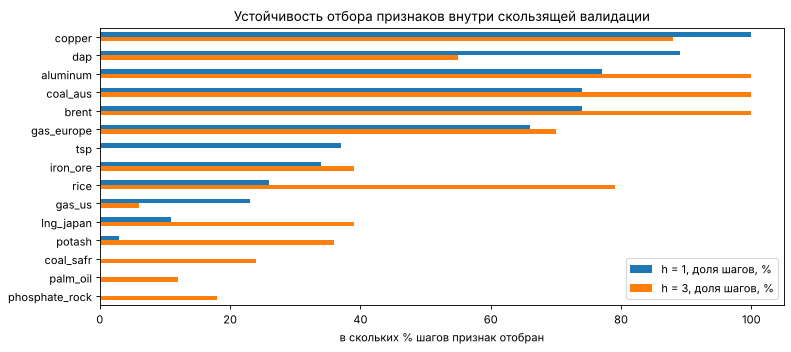

In [ ]:
freq = {}
for h, lists in selected_by_h.items():
    counts = pd.Series([f for feats in lists for f in feats]).value_counts()
    freq[f"h = {h}, доля шагов, %"] = (counts / len(lists) * 100).round()
freq = pd.DataFrame(freq).fillna(0).astype(int).sort_values(list(freq)[0], ascending=False)
freq.index = freq.index.str.replace("d_", "", regex=False)
print(freq.to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
freq.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_xlabel("в скольких % шагов признак отобран")
ax.set_title("Устойчивость отбора признаков внутри скользящей валидации")
plt.tight_layout()
plt.show()

## Выводы строгой проверки

**1. Строгий вариант работает — и модель с отбором признаков обыгрывает наивный прогноз на горизонте 1 месяц.** Ridge, у которого признаки отбираются заново на каждом шаге только по известным данным, на валидации октябрь 2020 – сентябрь 2023 даёт **MSE на 10% меньше наивного** (0,90): вне кризиса — на 15% (0,85), в кризис — на 9% (0,91). В спокойном окне 2018–2021 — на 5% (0,95).

**2. На 3 месяца модель выигрывает только в спокойные периоды** (0,71–0,76), а в кризис проигрывает (1,58) — на длинном горизонте шоки 2021–2022 непредсказуемы по одним ценам. Нужны признаки шоков (проливы, ограничения экспорта Китая).

**3. Отбор признаков нужен.** Ridge на всех 19 признаках в спокойном окне проигрывает наивному (1,38–1,40), а с отбором — выигрывает (0,76–0,95): лишние признаки добавляют шум.

**4. k, оценённый внутри шага, неустойчив** (от 8 до 31 в зависимости от того, какие годы уже известны), и модель «возврат надбавки к норме» проигрывает наивному прогнозу (1,26–1,84). Поэтому для прогноза лучше моделировать **изменение цены**, а разложение «k × газ + надбавка» использовать для объяснения и сценариев, с k, зафиксированным заранее.

**5. Устойчивые признаки** — отбираются на большинстве шагов: медь, DAP, алюминий, уголь Австралии, нефть Brent, газ Европы. Это почти тот же набор, что в разделе 2.6 ноутбука 01_eda_prices_target (там он получен на всём трейне), — значит, отбор там не был случайным. Нестабильные (TSP, рис, железная руда, СПГ Японии) — отбираются от случая к случаю, их в базовый набор не берём.

**Что дальше:** этот же строгий бэктест используем для бейзлайнов к чекпоинту 3 и добавляем признаки команды (PortWatch, GSCPI, ограничения Китая). Тест (октябрь 2023 – сентябрь 2026) по-прежнему не трогаем.
